# Блок 7. Основы искусственного интеллекта и машинного обучения
# Занятие 4. Практика регрессии на датасете недвижимости

## Цель занятия

На прошлом занятии мы изучили линейную регрессию.

Сегодня будем работать как настоящий аналитик данных:

- использовать больше признаков;
- сравнивать качество модели;
- анализировать важность признаков;
- интерпретировать ошибки;
- строить графики;
- формировать бизнес-отчёт.

## Датасет

California Housing

https://raw.githubusercontent.com/ageron/handson-ml/master/datasets/housing/housing.csv

## Связь с дипломом

Это практически готовый шаблон для дипломов:

- недвижимость;
- продажи;
- финансы;
- медицина;
- спорт.


Сначала изучите SOLVED ноутбук, затем выполните TODO самостоятельно.

## Ячейка 1. Загрузка датасета

### Алгоритм
Загружаем реальные заболеваемости ВИЧ.

In [101]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('analytics_result.csv')


## Ячейка 2. Изучение признаков

### Алгоритм
Смотрим структуру данных.

In [83]:
# целевая переменная — заболеваемость ВИЧ
display(df.head())
print(df.columns.tolist())

assert "hiv_firstdiagnosis_100k" in df.columns


,Регион,hiv_therapy_regdispensaries,hiv_regdispensaries_numdetect,hiv_firstdiagnosis_100k,hiv_motherchild_chemoprophylaxis,число_впервые_выявленных,тестировано_россиян,тестировано_иностранцев,num_alldoctors_inmedorgservices,num_infectiousdoctors_inmedorgservices,per_infectious_inalldoctors,year,hiv_firstdiagnosis_100k_rounded,Название региона,high_incidence_flag
0,российская_федерация,28.6,65.8,52.9,85.7,75708.0,26037319.0,1248832.0,703220.0,7545.0,1.1,2012,53,20,0
1,российская_федерация,32.9,64.8,57.0,85.2,81698.0,26821308.0,1498666.0,702577.0,7461.0,1.1,2013,57,20,0
2,российская_федерация,36.4,66.0,63.3,84.2,92613.0,27982810.0,1895871.0,709397.0,6796.0,1.0,2014,63,20,0
3,российская_федерация,39.8,66.1,68.5,87.8,100220.0,28336911.0,2413636.0,673040.0,6622.0,1.0,2015,68,20,1
4,российская_федерация,72.4,42.5,59.3,88.0,86855.0,27982810.0,1895871.0,680916.0,6678.0,1.0,2016,59,20,0


['Регион', 'hiv_therapy_regdispensaries', 'hiv_regdispensaries_numdetect', 'hiv_firstdiagnosis_100k', 'hiv_motherchild_chemoprophylaxis', 'число_впервые_выявленных', 'тестировано_россиян', 'тестировано_иностранцев', 'num_alldoctors_inmedorgservices', 'num_infectiousdoctors_inmedorgservices', 'per_infectious_inalldoctors', 'year', 'hiv_firstdiagnosis_100k_rounded', 'Название региона', 'high_incidence_flag']


## Ячейка 3. Подготовка данных

### Алгоритм
Выбираем больше признаков.

In [84]:
#Коэффициент региона показывает, насколько заболеваемость в этом регионе отличается от базового.
#Отрицательный → заболеваемость ниже базовой
#Положительный → заболеваемость выше базовой
#Большой по модулю → регион сильно отличается

# Убрала строки "Российская Федерация" и федеральные округи, чтобы модель работала точнее
# На практике эта ячейка оказалась ОЧЕНЬ важной, результат разительно отличается от того, что получила в том же ноутбуке №3

# ОЧИСТКА (ДО One-Hot!)

df = df[df['Регион'] != 'российская_федерация']
df = df[~df['Регион'].str.contains('федеральный_округ', case=False, na=False)]

print(f"Строк после очистки: {len(df)}")

# ONE-HOT ENCODING

df_encoded = pd.get_dummies(df, columns=['Регион'], drop_first=True, dtype=int)

region_cols = [col for col in df_encoded.columns if col.startswith('Регион_')]
print(f"Колонок регионов: {len(region_cols)}")


# ПРИЗНАКИ И ЦЕЛЬ

features_base = [
    'hiv_therapy_regdispensaries',
    'hiv_regdispensaries_numdetect',
    'hiv_motherchild_chemoprophylaxis',
    'число_впервые_выявленных',
    'тестировано_россиян',
    'тестировано_иностранцев',
    'num_alldoctors_inmedorgservices',
    'num_infectiousdoctors_inmedorgservices',
    'per_infectious_inalldoctors',
    'year'
]

features = features_base + region_cols
target = 'hiv_firstdiagnosis_100k'

X = df_encoded[features]
y = df_encoded[target]

print(f"\nПризнаков всего: {len(features)}")
print(f"  Базовых: {len(features_base)}")
print(f"  Регионов: {len(region_cols)}")


# УБИРАЕМ ПРОПУСКИ

data = pd.concat([X, y], axis=1).dropna()
X = data[features]
y = data[target]

print(f"\nРазмер X: {X.shape}")
print(f"Размер y: {y.shape}")
print(f"Пропусков в X: {X.isna().sum().sum()}")
print(f"Пропусков в y: {y.isna().sum()}")

Строк после очистки: 680
Колонок регионов: 84

Признаков всего: 94
  Базовых: 10
  Регионов: 84

Размер X: (680, 94)
Размер y: (680,)
Пропусков в X: 0
Пропусков в y: 0


## Ячейка 4. Разделение данных

### Алгоритм
Train/Test Split.

In [85]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(f"Всего строк: {len(X)}")
print(f"\nОбучающая выборка (train):")
print(f"  X_train: {X_train.shape}")
print(f"  y_train: {y_train.shape}")
print(f"\nТестовая выборка (test):")
print(f"  X_test: {X_test.shape}")
print(f"  y_test: {y_test.shape}")

Всего строк: 680

Обучающая выборка (train):
  X_train: (544, 94)
  y_train: (544,)

Тестовая выборка (test):
  X_test: (136, 94)
  y_test: (136,)


## Ячейка 5. Масштабирование

### Алгоритм
Используем StandardScaler.

In [86]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)  # обучаем + применяем
X_test_scaled = scaler.transform(X_test)        # только применяем!

print(f"\nПосле масштабирования:")
print(f"X_train_scaled: {X_train_scaled.shape}")
print(f"X_test_scaled: {X_test_scaled.shape}")


После масштабирования:
X_train_scaled: (544, 94)
X_test_scaled: (136, 94)


## Ячейка 6. Обучение модели

### Алгоритм
Строим LinearRegression.

In [87]:
#Масштабируем X (признаки) — и train, и test
#НЕ масштабируем y (цель)
#fit_transform — только на train
#transform — на test

model = LinearRegression()
model.fit(X_train_scaled,y_train)

assert model is not None
from sklearn.metrics import r2_score

y_pred_train = model.predict(X_train_scaled)
y_pred_test = model.predict(X_test_scaled)

r2_train = r2_score(y_train, y_pred_train)

r2_test = r2_score(y_test, y_pred_test)

print(f"R² на train: {r2_train:.4f}")
print(f"R² на test:  {r2_test:.4f}")

#На выводе разница с ноутбуком №3 ОГРОМНАЯ


R² на train: 0.9484
R² на test:  0.9563


## Ячейка 7. Важность признаков

### Алгоритм
Анализируем коэффициенты.

In [88]:
#Вывела коэффициенты с помощью zip
#Коэффициенты обучились на train (80%), применились для всего датасета, фиксированны после обучения

for feature, coef in zip(X.columns, model.coef_):
    print(f"{feature}: {coef:.2f}")

hiv_therapy_regdispensaries: -2.19
hiv_regdispensaries_numdetect: -1.38
hiv_motherchild_chemoprophylaxis: -3.09
число_впервые_выявленных: 31.48
тестировано_россиян: -0.24
тестировано_иностранцев: 1.96
num_alldoctors_inmedorgservices: -7.06
num_infectiousdoctors_inmedorgservices: -2.68
per_infectious_inalldoctors: 0.59
year: 4.82
Регион_амурская_область: -4.00
Регион_архангельская_область: -2.85
Регион_астраханская_область: -2.63
Регион_белгородская_область: -3.37
Регион_брянская_область: -2.41
Регион_владимирская_область: -1.67
Регион_волгоградская_область: -1.46
Регион_вологодская_область: -2.57
Регион_воронежская_область: -2.40
Регион_г._москва: -5.29
Регион_г._санкт-петербург: -3.02
Регион_г._севастополь: -0.03
Регион_еврейская_автономная_область: -3.39
Регион_забайкальский_край: -1.21
Регион_ивановская_область: 0.42
Регион_иркутская_область: 2.30
Регион_кабардино-балкарская_республика: -3.56
Регион_калининградская_область: -1.03
Регион_калужская_область: -2.77
Регион_камчатский_кра

In [89]:
#Дополнительная ячейка для удобочитаемости с сортировкой по важности

# Создаём DataFrame с коэффициентами
coef_df = pd.DataFrame({
    'Признак': X.columns,
    'Коэффициент': model.coef_
})

# Сортируем по модулю коэффициента (от большего к меньшему)
coef_df['abs_coef'] = coef_df['Коэффициент'].abs()
coef_df = coef_df.sort_values('abs_coef', ascending=False).drop(columns='abs_coef')

print("Топ-20 важных признаков:")
print(coef_df.head(20).to_string(index=False))

Топ-20 важных признаков:
                               Признак  Коэффициент
              число_впервые_выявленных    31.476218
       num_alldoctors_inmedorgservices    -7.055748
                      Регион_г._москва    -5.285814
             Регион_московская_область    -5.079737
                                  year     4.820293
            Регион_республика_калмыкия    -4.685738
                Регион_республика_тыва    -4.312164
             Регион_краснодарский_край    -4.170624
                Регион_томская_область     4.048498
               Регион_амурская_область    -3.999438
           Регион_чеченская_республика    -3.901128
           Регион_республика_ингушетия    -3.874622
            Регион_кемеровская_область     3.819390
       Регион_республика_саха_(якутия)    -3.795672
             Регион_ростовская_область    -3.720442
Регион_карачаево-черкесская_республика    -3.709794
              Регион_кировская_область    -3.675120
              Регион_тюменская_область 

## Ячейка 8. Прогнозирование


### Алгоритм
Делаем прогноз.

In [95]:
# При анализе ошибок модели было выявлено, что наибольшие ошибки связаны с регионами, имеющими аномально высокую заболеваемость (например, Иркутская и Кемеровская области). 
# Эти регионы являются выбросами в данных: их показатели (130–240 на 100 тыс.) значительно превышают средние по стране (20–80).

y_pred = model.predict(X_test_scaled)

# Сравнила предсказания с реальными значениями
comparison = pd.DataFrame({
    'Реальные': y_test.values[:15],
    'Предсказанные': y_pred[:15].round(2),
    'Ошибка': (y_test.values[:15] - y_pred[:15]).round(2)
})

print(comparison)


    Реальные  Предсказанные  Ошибка
0        9.3          13.07   -3.77
1       64.7          68.17   -3.47
2       44.1          50.51   -6.41
3       91.7          94.27   -2.57
4       61.8          55.07    6.73
5      132.0         135.82   -3.82
6       35.2          25.35    9.85
7       45.8          34.32   11.48
8       37.6          58.23  -20.63
9        6.6           1.67    4.93
10      37.1          41.83   -4.73
11      59.5          62.19   -2.69
12      69.0          61.38    7.62
13      16.7          16.72   -0.02
14     148.4         153.00   -4.60


## Ячейка 9. Метрики качества

### Алгоритм
Считаем MAE RMSE R2.

In [100]:
#Модель отличного качества!
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)

print("MAE",round(mae, 2))
print("MSE",round(mse, 2))
print("RMSE",round(rmse, 2))
print("R2",round(r2, 2))

MAE 6.29
MSE 78.06
RMSE 8.83
R2 0.96


## Ячейка 10. Визуализация

### Алгоритм
Строим графики качества.

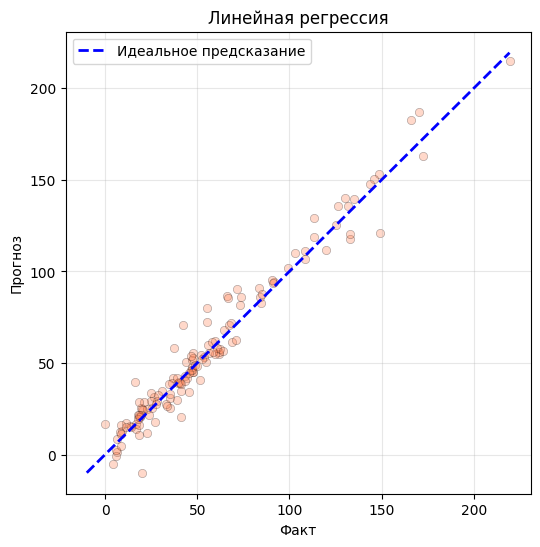

In [102]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='coral', edgecolor='black', linewidth=0.5)

# Идеальное предсказание" — это прямая линия y = x, которая показывает, где были бы точки, если бы модель предсказывала идеально (без ошибок).
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'b--', linewidth=2, label='Идеальное предсказание')

plt.xlabel("Факт")
plt.ylabel("Прогноз")
plt.title("Линейная регрессия")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

assert True

## Ячейка 11. Мини-проект

### Алгоритм
Формируем бизнес-отчет.

In [104]:
report = {
    "rows": len(X),
    "features": len(X.columns),
    "MAE": round(float(mae), 2),
    "RMSE": round(float(rmse), 2),
    "R2": round(float(r2), 3)
}

print(report)


{'rows': 680, 'features': 94, 'MAE': 6.29, 'RMSE': 8.83, 'R2': 0.956}
